# Yelp Rating Regression Predictor

This project makes use of restaurant data provided by Yelp (via Codecademy) in order to use Multiple Linear Regression to investigate what factors most affect a restaurant's Yelp rating and predict the Yelp rating for a hypothetical restaurant. Unfortunately, we do not have permission to distribute the data provided by Yelp, so this notebook mainly stands as an archive of the code and methods that were used with the data. The data is available to the public via Codecademy's "Build a Machine Learning Model" course.

We start by importing pandas and reading the data from files into DataFrames.

In [26]:
import pandas as pd
businesses = pd.read_json('yelp_business.json', lines=True)
reviews = pd.read_json('yelp_review.json', lines=True)
users = pd.read_json('yelp_user.json', lines=True)
checkins = pd.read_json('yelp_checkin.json', lines=True)
tips = pd.read_json('yelp_tip.json', lines=True)
photos = pd.read_json('yelp_photo.json', lines=True)

Examples of the data and information such as data types can be inspected with *.head()* and *info()* methods. Due to the size of the data, we also restrict displayed column number and width.

In [27]:
pd.options.display.max_columns = 60
pd.options.display.max_colwidth = 500

We can check some relevant statistics using the DataFrames, such as the number of individual businesses by counting the unique ids:

In [28]:
businesses['business_id'].nunique()

188593

Or get statistics within the columns of the individual DataFrames:

In [29]:
users.describe()

,average_number_friends,average_days_on_yelp,average_number_fans,average_review_count,average_number_years_elite
count,188593.000000,188593.000000,188593.000000,188593.000000,188593.000000
mean,105.132000,2005.367009,11.590148,122.110660,0.923313
std,162.653680,554.174540,25.901801,208.814471,1.109289
min,1.000000,76.000000,0.000000,0.666667,0.000000
25%,26.666667,1647.000000,0.666667,21.000000,0.000000
50%,59.384615,1957.150000,3.583333,62.142857,0.583333
75%,117.666667,2312.238095,11.555556,143.454545,1.400000
max,4219.000000,4860.000000,1174.666667,6335.000000,10.666667


And even access individual data within DataFrames:

In [30]:
businesses[businesses['business_id'] == '5EvUIR4IzCWUOm0PsUZXjA']['stars']

30781    3.0
Name: stars, dtype: float64

## Merging and Cleaning Data
We have multiple DataFrames produced by reading the six files. In order to do any analysis we will need to merge these, cleaning if necessary. We will start left merging with *businesses* as the original left DataFrame to discard any rows in other DataFrames that do not correspond to a business we have full data on, using the *business_id* as the target. We then examine all the columns of this full DataFrame.

In [31]:
df = pd.merge(businesses, reviews, how='left', on='business_id')
df = pd.merge(df, users, how='left', on='business_id')
df = pd.merge(df, checkins, how='left', on='business_id')
df = pd.merge(df, tips, how='left', on='business_id')
df = pd.merge(df, photos, how='left', on='business_id')
print(df.columns)

Index(['address', 'alcohol?', 'attributes', 'business_id', 'categories',
       'city', 'good_for_kids', 'has_bike_parking', 'has_wifi', 'hours',
       'is_open', 'latitude', 'longitude', 'name', 'neighborhood',
       'postal_code', 'price_range', 'review_count', 'stars', 'state',
       'take_reservations', 'takes_credit_cards', 'average_review_age',
       'average_review_length', 'average_review_sentiment',
       'number_funny_votes', 'number_cool_votes', 'number_useful_votes',
       'average_number_friends', 'average_days_on_yelp', 'average_number_fans',
       'average_review_count', 'average_number_years_elite', 'time',
       'weekday_checkins', 'weekend_checkins', 'average_tip_length',
       'number_tips', 'average_caption_length', 'number_pics'],
      dtype='str')


As we will be performing a Multiple Linear Regression to predict Yelp ratings, we can remove any of the above features that are not continuous variables, or a Boolean type value.

In [32]:
features_to_remove = ['address','attributes','business_id','categories','city','hours','is_open','latitude','longitude','name','neighborhood','postal_code','state','time']
df.drop(labels=features_to_remove, axis=1, inplace=True)

We can then check if there are any missing NaN values in our data which would cause the model to fail.

In [33]:
df.isna().any()

alcohol?                      False
good_for_kids                 False
has_bike_parking              False
has_wifi                      False
price_range                   False
review_count                  False
stars                         False
take_reservations             False
takes_credit_cards            False
average_review_age            False
average_review_length         False
average_review_sentiment      False
number_funny_votes            False
number_cool_votes             False
number_useful_votes           False
average_number_friends        False
average_days_on_yelp          False
average_number_fans           False
average_review_count          False
average_number_years_elite    False
weekday_checkins               True
weekend_checkins               True
average_tip_length             True
number_tips                    True
average_caption_length         True
number_pics                    True
dtype: bool

Given that the columns with missing values are things like "caption length" and "number of pictures" we can fill these missing data with zero values as the feature was missing from the business, rather than removing these rows.

In [34]:
df.fillna({'weekday_checkins':0,
           'weekend_checkins':0,
           'average_tip_length':0,
           'number_tips':0,
           'average_caption_length':0,
           'number_pics':0},
          inplace=True)

,alcohol?,good_for_kids,has_bike_parking,has_wifi,price_range,review_count,stars,take_reservations,takes_credit_cards,average_review_age,average_review_length,average_review_sentiment,number_funny_votes,number_cool_votes,number_useful_votes,average_number_friends,average_days_on_yelp,average_number_fans,average_review_count,average_number_years_elite,weekday_checkins,weekend_checkins,average_tip_length,number_tips,average_caption_length,number_pics
0,0,1,0,0,2,24,4.0,1,1,618.250000,532.916667,0.865342,6,5,13,42.833333,1809.375000,5.375000,114.875000,1.125000,11.0,18.0,38.000000,6.0,0.0,0.0
1,0,1,0,0,2,3,4.5,0,1,371.666667,481.333333,0.975000,0,1,1,64.333333,970.333333,2.666667,19.666667,0.666667,0.0,1.0,66.000000,1.0,29.0,1.0
2,1,1,1,1,2,5,4.0,1,0,1106.200000,252.000000,0.301240,0,2,1,4.200000,1499.600000,1.000000,24.600000,0.600000,2.0,5.0,32.000000,1.0,0.0,0.0
3,0,0,0,0,0,8,1.5,0,0,398.500000,672.625000,-0.060500,1,0,3,12.500000,1626.500000,2.375000,68.000000,0.250000,1.0,0.0,0.000000,0.0,0.0,0.0
4,0,0,0,0,0,4,2.0,0,1,1412.750000,1015.500000,0.372550,0,0,4,137.750000,2570.000000,26.750000,528.250000,4.250000,2.0,0.0,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188588,0,0,0,0,1,9,2.5,0,1,1945.111111,534.222222,-0.155056,2,0,7,12.888889,2110.333333,0.333333,40.222222,0.000000,2.0,1.0,0.000000,0.0,0.0,0.0
188589,0,0,0,0,0,5,2.0,0,0,1399.800000,810.600000,-0.348260,3,1,26,5.200000,2104.800000,0.600000,3.400000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0
188590,0,0,1,0,1,26,3.0,0,1,1565.653846,631.846154,0.451092,41,45,64,242.192308,2686.769231,37.692308,608.653846,2.576923,240.0,307.0,55.214286,14.0,0.0,0.0
188591,0,0,0,1,2,19,4.0,0,1,1104.894737,788.789474,0.718642,31,49,50,112.263158,1943.842105,14.789474,112.789474,0.684211,31.0,27.0,44.800000,5.0,0.0,0.0


## Selecting Data

We can make use of the *.corr()* method to check how well the data in the various columns correlates. This can give us an idea of which variables to include in our model.

In [35]:
df.corr()

,alcohol?,good_for_kids,has_bike_parking,has_wifi,price_range,review_count,stars,take_reservations,takes_credit_cards,average_review_age,average_review_length,average_review_sentiment,number_funny_votes,number_cool_votes,number_useful_votes,average_number_friends,average_days_on_yelp,average_number_fans,average_review_count,average_number_years_elite,weekday_checkins,weekend_checkins,average_tip_length,number_tips,average_caption_length,number_pics
alcohol?,1.000000,0.305284,0.213318,0.345032,0.349004,0.259836,-0.043332,0.601670,0.190738,0.139108,0.037369,0.097188,0.117472,0.188598,0.165775,0.015261,0.129901,0.017794,0.026846,0.099141,0.094398,0.131175,0.098037,0.208856,0.305570,0.252523
good_for_kids,0.305284,1.000000,0.271788,0.258887,0.205513,0.162469,-0.030382,0.318729,0.150360,0.055847,-0.079183,0.073806,0.060658,0.113262,0.083832,0.016557,0.045057,0.024901,0.040692,0.094233,0.068960,0.079808,0.121948,0.156536,0.291413,0.175058
has_bike_parking,0.213318,0.271788,1.000000,0.235138,0.416044,0.155505,0.068084,0.160129,0.286298,-0.080443,-0.116295,0.130448,0.060595,0.114094,0.094000,0.028307,-0.045849,0.018120,0.031203,0.083062,0.082474,0.093579,0.144163,0.147115,0.180468,0.109552
has_wifi,0.345032,0.258887,0.235138,1.000000,0.240796,0.195737,-0.039857,0.312217,0.155098,-0.034258,-0.037712,0.054699,0.082213,0.147320,0.120622,0.015937,0.000448,0.023913,0.044006,0.082863,0.107467,0.126861,0.104742,0.173542,0.258938,0.210583
price_range,0.349004,0.205513,0.416044,0.240796,1.000000,0.148277,-0.052565,0.316105,0.400742,0.189623,0.003850,0.089349,0.073215,0.119422,0.098990,0.087231,0.176133,0.104221,0.122982,0.210487,0.057877,0.081321,0.129212,0.119632,0.170171,0.143570
review_count,0.259836,0.162469,0.155505,0.195737,0.148277,1.000000,0.032413,0.187755,0.119984,0.010070,0.004748,0.076265,0.548164,0.860767,0.746949,0.026206,0.050451,0.000474,-0.002576,0.014712,0.567452,0.699631,0.094133,0.844978,0.224983,0.610889
stars,-0.043332,-0.030382,0.068084,-0.039857,-0.052565,0.032413,1.000000,-0.024486,0.037748,-0.125645,-0.277081,0.782187,0.001320,0.043375,-0.000066,-0.007629,-0.038061,-0.031141,-0.066572,-0.064419,0.004130,0.007863,-0.052899,0.014038,0.000040,0.001727
take_reservations,0.601670,0.318729,0.160129,0.312217,0.316105,0.187755,-0.024486,1.000000,0.127941,0.064098,0.046331,0.086728,0.071131,0.129165,0.115583,-0.025522,0.048850,0.001131,0.010618,0.063990,0.053162,0.076183,0.084098,0.134832,0.282823,0.231242
takes_credit_cards,0.190738,0.150360,0.286298,0.155098,0.400742,0.119984,0.037748,0.127941,1.000000,0.056399,-0.081383,0.084171,0.049945,0.079879,0.077804,0.027924,0.078443,-0.007124,-0.005260,0.009551,0.047402,0.055898,0.119925,0.097700,0.103271,0.073276
average_review_age,0.139108,0.055847,-0.080443,-0.034258,0.189623,0.010070,-0.125645,0.064098,0.056399,1.000000,0.192355,0.003662,0.032199,0.031577,0.028122,0.218990,0.820888,0.243377,0.261623,0.377335,0.030324,0.035531,-0.000525,0.050846,-0.024121,-0.041140


We can see that the three features that correlate most with Yelp rating are `average_review_sentiment`, `average_review_length`, `average_review_age`, with the rest correlating fairly weakly. We can create models based on just these variables, all variables, or any combinations. As a more explicit example we start with just the `average_review_length` and `average_review_age` columns.

## Training a Model
We first need to select the variables, and split into training and testing data sets. We do this by importing methods from *sklearn*.

In [36]:
from sklearn.model_selection import train_test_split
features = df[['average_review_length','average_review_age']]
ratings = df['stars']

X_train, X_test, y_train, y_test = train_test_split(features, ratings, test_size = 0.2, random_state = 1)

And now we can fit a Linear Regression model to the training data:

In [37]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['average_review_length','average_review_age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.36
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


We can check the model in a number of ways. Starting with the *.score()* method which returns a value between 0 and 1, we can see this model is not particularly accurate:

In [38]:
print(model.score(X_train,y_train))
print(model.score(X_test,y_test))

0.082503095665449
0.08083081210060539


We can also plot the predicted Yelp ratings of our model against the actual ratings, where we would expect to see a linear *y=x* relationship for a perfect model. As we can see below, this model is not very successful:

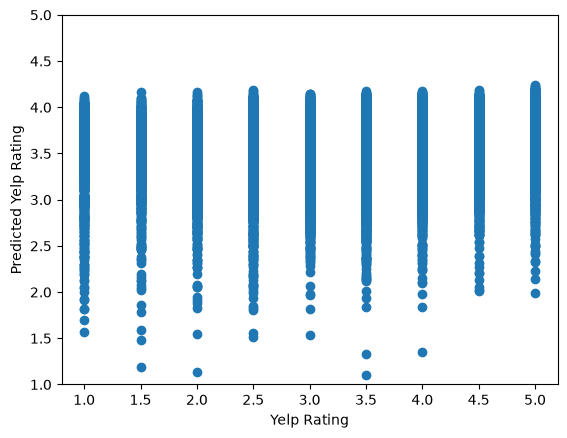

In [39]:
from matplotlib import pyplot as plt
y_predicted = model.predict(X_test)
plt.scatter(y_test,y_predicted)
plt.xlabel('Yelp Rating')
plt.ylabel('Predicted Yelp Rating')
plt.ylim(1,5)
plt.show()

## Further Modelling
We can see that this model is not particularly accurate. We should definitely be including the `average_review_sentiment` variable which had the greatest correlation earlier. We can in fact include all of our different features, as well as testing the Boolean and continuous type variables separately:

In [46]:
# subset of only average review sentiment
sentiment = ['average_review_sentiment']
# subset of all features that have a response range [0,1]
boolean_features = ['alcohol?','has_bike_parking','takes_credit_cards','good_for_kids','take_reservations','has_wifi']
# subset of all features that vary on a greater range than [0,1]
numeric_features = ['review_count','price_range','average_caption_length','number_pics','average_review_age','average_review_length','average_review_sentiment','number_funny_votes','number_cool_votes','number_useful_votes','average_tip_length','number_tips','average_number_friends','average_days_on_yelp','average_number_fans','average_review_count','average_number_years_elite','weekday_checkins','weekend_checkins']
# all features
all_features = numeric_features + boolean_features

We now create a function that we can feed each of these subsets into and produce a model that will predict from the data. This prevents us having to do all the steps above repeatedly.

In [41]:
import numpy as np

def model_these_features(feature_list):
    
    ratings = df.loc[:,'stars']
    features = df.loc[:,feature_list]
    
    X_train, X_test, y_train, y_test = train_test_split(features, ratings, test_size = 0.2, random_state = 1)

    #Reshape data to work with Multiple Linear Regression model from skLearn
    if len(X_train.shape) < 2:
        X_train = np.array(X_train).reshape(-1,1)
        X_test = np.array(X_test).reshape(-1,1)
    
    model = LinearRegression()
    model.fit(X_train,y_train)

    print('Train Score:', model.score(X_train,y_train))
    print('Test Score:', model.score(X_test,y_test))
    
    # print the model features and their corresponding coefficients, from most predictive to least predictive
    print(sorted(list(zip(feature_list,model.coef_)),key = lambda x: abs(x[1]),reverse=True))

        
    # plot actual Yelp Ratings vs the predicted Yelp ratings
    y_predicted = model.predict(X_test)
    plt.scatter(y_test,y_predicted)
    plt.xlabel('Yelp Rating')
    plt.ylabel('Predicted Yelp Rating')
    plt.ylim(1,5)
    plt.show()

We can then use this function and see how well the four different feature sets model the data!

Train Score: 0.6118980950438655
Test Score: 0.6114021046919491
[('average_review_sentiment', np.float64(2.3033908433749652))]


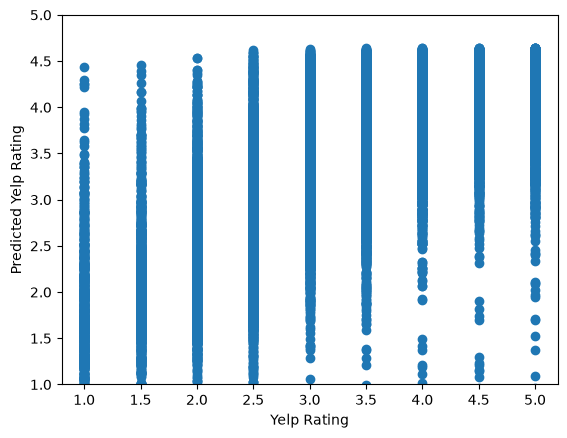

In [42]:
model_these_features(sentiment)

Train Score: 0.012223180709591608
Test Score: 0.01011954220226885
[('has_bike_parking', np.float64(0.19003008208038158)), ('alcohol?', np.float64(-0.14549670708137585)), ('has_wifi', np.float64(-0.1318739757776216)), ('good_for_kids', np.float64(-0.08632485990338187)), ('takes_credit_cards', np.float64(0.07175536492195617)), ('take_reservations', np.float64(0.045265585304514695))]


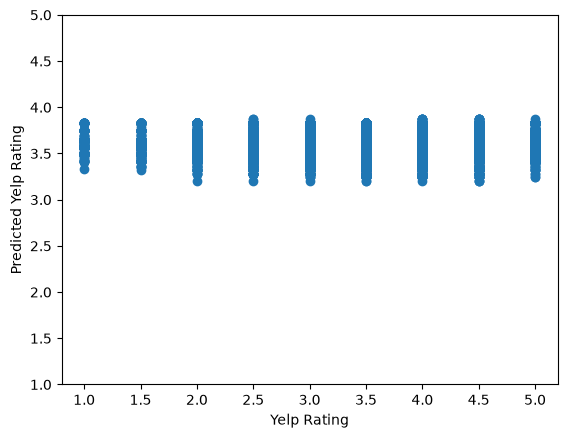

In [43]:
model_these_features(boolean_features)

Train Score: 0.673499259376666
Test Score: 0.6713318798120137
[('average_review_sentiment', np.float64(2.272107664209648)), ('price_range', np.float64(-0.08046080962700002)), ('average_number_years_elite', np.float64(-0.07190366288054358)), ('average_caption_length', np.float64(-0.0033470660077852257)), ('number_pics', np.float64(-0.0029565028128939984)), ('number_tips', np.float64(-0.0015953050789024705)), ('number_cool_votes', np.float64(0.0011468839227084457)), ('average_number_fans', np.float64(0.0010510602097421348)), ('average_review_length', np.float64(-0.0005813655692095284)), ('average_tip_length', np.float64(-0.0005322032063459969)), ('number_useful_votes', np.float64(-0.00023203784758744905)), ('average_review_count', np.float64(-0.00022431702895004047)), ('average_review_age', np.float64(-0.00016930608165074707)), ('average_days_on_yelp', np.float64(0.00012878025876700543)), ('weekday_checkins', np.float64(5.9185807545047986e-05)), ('weekend_checkins', np.float64(-5.5181762

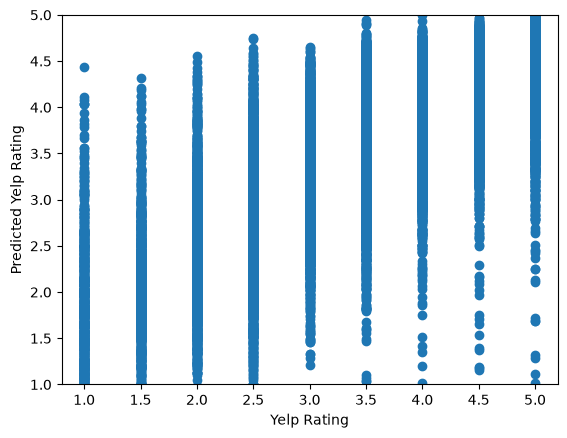

In [44]:
model_these_features(numeric_features)

Train Score: 0.6807828861895335
Test Score: 0.6782129045869251
[('average_review_sentiment', np.float64(2.2808456996623625)), ('alcohol?', np.float64(-0.14991498593469912)), ('has_wifi', np.float64(-0.12155382629262798)), ('good_for_kids', np.float64(-0.11807814422012516)), ('price_range', np.float64(-0.06486730150043288)), ('average_number_years_elite', np.float64(-0.06278939713895626)), ('has_bike_parking', np.float64(0.027296969912258776)), ('takes_credit_cards', np.float64(0.02445183785363373)), ('take_reservations', np.float64(0.0141345591729718)), ('number_pics', np.float64(-0.001313361230080569)), ('average_number_fans', np.float64(0.0010267986822650942)), ('number_cool_votes', np.float64(0.0009723722734404222)), ('number_tips', np.float64(-0.0008546563320884271)), ('average_caption_length', np.float64(-0.0006472749798169688)), ('average_review_length', np.float64(-0.0005896257920272442)), ('average_tip_length', np.float64(-0.0004205217503406595)), ('number_useful_votes', np.flo

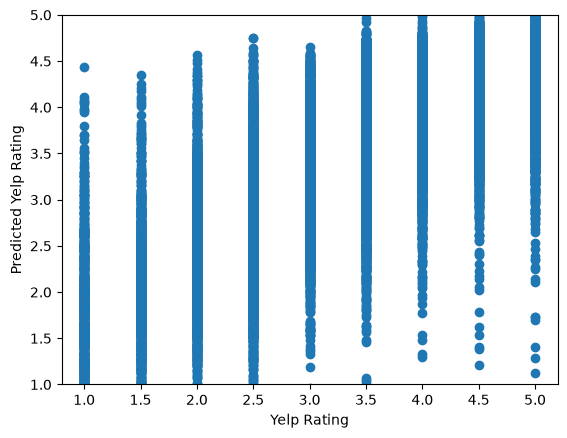

In [47]:
model_these_features(all_features)

From the above, we can see that using all the features produces the best model, perhaps unsurprisingly. The `average_review_sentiment` variable has by far the greatest impact, and because of this the *numeric_features* model is much better than the *boolean_features* model.

## Predicting a New Rating
Using a model with all features, we can then make a prediction for the Yelp rating of a new hypothetical restaurant! Firstly we train the model again outside of our function for use:

In [55]:
features = df.loc[:,all_features]
ratings = df.loc[:,'stars']
X_train, X_test, y_train, y_test = train_test_split(features.to_numpy(), ratings, test_size = 0.2, random_state = 1)
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](25,)","[ 0. ,-0.06,-0. ,...,-0.12, 0.01,-0.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.856
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(25)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](25,)","[322294.39,167401.26,102577.54,..., 127.6 , 110.79, 78.53]"


We can recall all the different features:

In [49]:
print(all_features)

['review_count', 'price_range', 'average_caption_length', 'number_pics', 'average_review_age', 'average_review_length', 'average_review_sentiment', 'number_funny_votes', 'number_cool_votes', 'number_useful_votes', 'average_tip_length', 'number_tips', 'average_number_friends', 'average_days_on_yelp', 'average_number_fans', 'average_review_count', 'average_number_years_elite', 'weekday_checkins', 'weekend_checkins', 'alcohol?', 'has_bike_parking', 'takes_credit_cards', 'good_for_kids', 'take_reservations', 'has_wifi']


And pick some values for a hypothetical restaurant. Running this through the prediction of our model produces the predicted Yelp rating!

In [56]:
hypothetical = np.array([0,1,1,1,1,1,10,2,3,10,10,1200,0.9,3,6,5,50,3,50,1800,12,123,0.5,0,0]).reshape(1,-1)
model.predict(hypothetical)

array([-245.14219147])